
# Challenge Sprint 3 — Modelagem Matemática e Computacional

## Integrantes

| RM | Nome |
|---|---|
| 571836 | Bruna Yukimy Hada |
| 571562 | Denize Ferrante |
| 570436 | Gabriel Del Pizzo Pintor |
| 572395 | Gabriel Dias Menezes |
| 570540 | Ian Rodrigues Martins |
| 572899 | Patrick Fernandes Martins Pais |

----

## Cálculo Integral aplicado à Orquestração de Energia

**Tema:** transformação de potência instantânea em energia entregue ao longo do tempo.

Neste notebook serão analisadas as curvas de potência de dois produtos do ecossistema EV Challenge 2026:

- **ChargeGrid Intelligence — Posto 1:** uso comercial/varejo.
- **EV ChargeOps — Posto 2:** uso condominial/residencial.

O objetivo é calcular a energia entregue em diferentes intervalos do dia utilizando **integral definida**, combinando:

1. resolução analítica das integrais;
2. cálculo simbólico com **Python + SymPy**;
3. visualização das curvas de potência;
4. comparação dos resultados e interpretação de negócio.

> **Observação:** no enunciado, o símbolo `p` representa a constante matemática **π (pi)**. Portanto, as funções serão implementadas usando `sp.pi`.


## 1. Fundamentação matemática

Potência é a taxa de transferência de energia ao longo do tempo. Quando a potência é dada por uma função contínua $P(t)$ em kW, a energia entregue entre os instantes $a$ e $b$ é calculada por:

$$E = \int_a^b P(t) \, dt$$

Como $1 \text{ kW} = 1 \text{ kWh/h}$ e $t$ está sendo medido em horas, o resultado da integral será dado em **kWh**.

As funções fornecidas são:

### Posto 1 — ChargeGrid Intelligence

$$P_1(t) = 5 + 20 \sin\left(\frac{\pi t}{24}\right)$$

### Posto 2 — EV ChargeOps

$$P_2(t) = 16 + 15 \cos\left(\frac{\pi(t - 20)}{12}\right)$$

com $0 \le t \le 24$.

A interpretação é importante: a **altura da curva** representa a potência instantânea, enquanto a **área sob a curva** em um intervalo representa a energia acumulada naquele período.

In [1]:

import sympy as sp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Variável simbólica que representa o horário em horas
t = sp.symbols('t', real=True)

# Funções de potência em kW
P1 = 5 + 20 * sp.sin(sp.pi * t / 24)
P2 = 16 + 15 * sp.cos(sp.pi * (t - 20) / 12)

print("P1(t) =", P1)
print("P2(t) =", P2)


P1(t) = 20*sin(pi*t/24) + 5
P2(t) = 15*cos(pi*(t/12 - 5/3)) + 16


## 2. Antiderivadas das funções

Antes de calcular cada intervalo, podemos encontrar uma antiderivada para cada função.

### 2.1 Posto 1

$$P_1(t) = 5 + 20 \sin\left(\frac{\pi t}{24}\right)$$

Sabemos que:

$$\int 5 \, dt = 5t$$

e, usando a regra:

$$\int \sin(at) \, dt = -\frac{\cos(at)}{a}$$

temos:

$$\int 20 \sin\left(\frac{\pi t}{24}\right) dt = -\frac{20}{\pi/24} \cos\left(\frac{\pi t}{24}\right)$$

$$= -\frac{480}{\pi} \cos\left(\frac{\pi t}{24}\right)$$

Portanto:

$$F_1(t) = 5t - \frac{480}{\pi} \cos\left(\frac{\pi t}{24}\right)$$

---

### 2.2 Posto 2

$$P_2(t) = 16 + 15 \cos\left(\frac{\pi(t - 20)}{12}\right)$$

Sabemos que:

$$\int 16 \, dt = 16t$$

e:

$$\int \cos(at + b) \, dt = \frac{1}{a} \sin(at + b)$$

Como $a = \frac{\pi}{12}$, então:

$$\int 15 \cos\left(\frac{\pi(t - 20)}{12}\right) dt = \frac{15}{\pi/12} \sin\left(\frac{\pi(t - 20)}{12}\right)$$

$$= \frac{180}{\pi} \sin\left(\frac{\pi(t - 20)}{12}\right)$$

Assim:

$$F_2(t) = 16t + \frac{180}{\pi} \sin\left(\frac{\pi(t - 20)}{12}\right)$$

In [2]:

# Antiderivadas calculadas simbolicamente pelo SymPy
F1 = sp.integrate(P1, t)
F2 = sp.integrate(P2, t)

print("Antiderivada de P1(t):")
print('\n')
sp.pprint(F1)

print("\nAntiderivada de P2(t):")
print('\n')
sp.pprint(F2)


Antiderivada de P1(t):


             ⎛π⋅t⎞
      480⋅cos⎜───⎟
             ⎝24 ⎠
5⋅t - ────────────
           π      

Antiderivada de P2(t):


              ⎛  ⎛t    5⎞⎞
       180⋅sin⎜π⋅⎜── - ─⎟⎟
              ⎝  ⎝12   3⎠⎠
16⋅t + ───────────────────
                π         



## 3. Gráfico das curvas de potência

O gráfico permite observar uma diferença importante entre **potência** e **energia**.

- Potência maior em determinado instante significa uma curva mais alta naquele momento.
- Energia maior em um intervalo significa uma **área maior sob a curva** naquele intervalo.

Os quatro intervalos pedidos serão destacados no gráfico:

- **Ex. 1:** `[0, 24]` — dia completo;
- **Ex. 2:** `[0, 6]` — madrugada/início da manhã;
- **Ex. 3:** `[10, 16]` — horário comercial;
- **Ex. 4:** `[18, 24]` — período noturno.


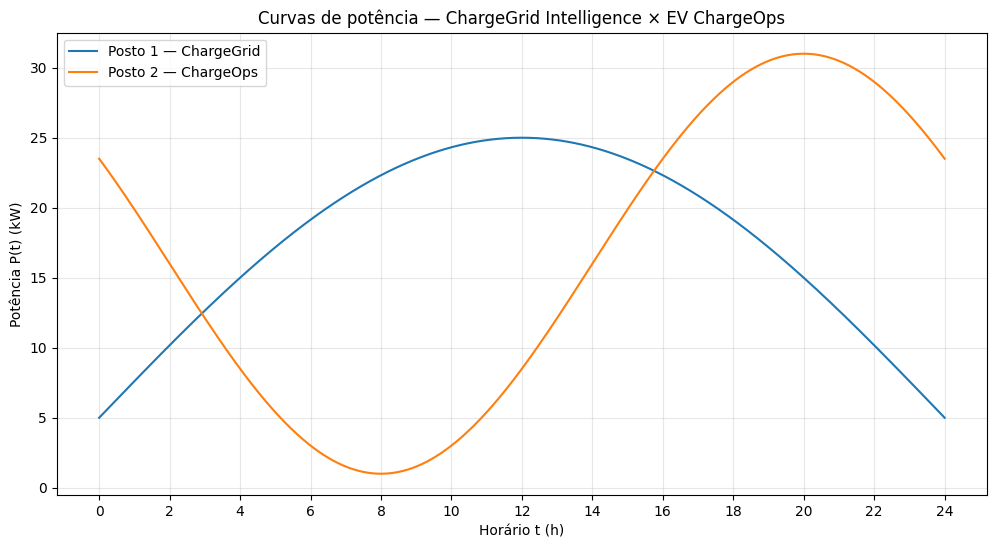

In [3]:

# Valores numéricos para desenhar as curvas
horas = np.linspace(0, 24, 1000)

p1_num = 5 + 20 * np.sin(np.pi * horas / 24)
p2_num = 16 + 15 * np.cos(np.pi * (horas - 20) / 12)

plt.figure(figsize=(12, 6))
plt.plot(horas, p1_num, label="Posto 1 — ChargeGrid")
plt.plot(horas, p2_num, label="Posto 2 — ChargeOps")

plt.xlabel("Horário t (h)")
plt.ylabel("Potência P(t) (kW)")
plt.title("Curvas de potência — ChargeGrid Intelligence × EV ChargeOps")
plt.xticks(np.arange(0, 25, 2))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 4. Funções de Exibição

Serão criadas algumas funções de formatação para melhorar a legibilidade e padronizar a exibição dos relatórios de consumo:

In [64]:
# Função para formatar os valores dos resultados
def valor_formatado(value):
    return round(float(value), 2)

# Função auxiliar para linhas divisórias
def linha(char="-", tamanho=70):
    print(char * tamanho)

# Função para exibir os dados individuais de cada posto
def exibe_resultado_posto(n_posto, energia, lim_i, lim_s):
    print(f"\n[ POSTO {n_posto} — Intervalo [{lim_i}, {lim_s}] h ]")
    print("• Expressão exata:   ")
    sp.pprint(energia)
    print(f"• Valor aproximado:  ≈ {valor_formatado(energia)} kWh")

def calcula_energia_periodo(lim_i, lim_s):
    limite = (t, lim_i, lim_s)
    energia_1 = sp.integrate(P1, limite)
    energia_2 = sp.integrate(P2, limite)
    return energia_1, energia_2

def exibe_relatorio(lim_i, lim_s, n_exc,energia_1,energia_2):
    diferenca = energia_1 - energia_2

    print("\n" + f" RELATÓRIO DE CONSUMO - EXERCÍCIO {n_exc} ".center(70, "="))
    exibe_resultado_posto(1, energia_1, lim_i, lim_s)
    linha()
    exibe_resultado_posto(2, energia_2, lim_i, lim_s)
    linha("=")
    print("\n[ COMPARATIVO ]")
    print(f"• Diferença (P1 - P2): ≈ {valor_formatado(diferenca)} kWh")
    linha("=")

# EXERCÍCIO 1 — Energia diária total

Precisamos calcular:

$$E_1 = \int_0^{24} P_1(t) \, dt$$

e:

$$E_2 = \int_0^{24} P_2(t) \, dt$$

---

## 1.1 Posto 1 — ChargeGrid

Substituindo a antiderivada:

$$E_1 = \left[ 5t - \frac{480}{\pi} \cos\left(\frac{\pi t}{24}\right) \right]_0^{24}$$

Aplicando o limite superior:

$$F_1(24) = 5(24) - \frac{480}{\pi} \cos(\pi)$$

Como $\cos(\pi) = -1$, então:

$$F_1(24) = 120 + \frac{480}{\pi}$$

Aplicando o limite inferior:

$$F_1(0) = 5(0) - \frac{480}{\pi} \cos(0)$$

Como $\cos(0) = 1$, temos:

$$F_1(0) = -\frac{480}{\pi}$$

Logo:

$$E_1 = F_1(24) - F_1(0)$$

$$E_1 = 120 + \frac{480}{\pi} - \left(-\frac{480}{\pi}\right)$$

$$E_1 = 120 + \frac{960}{\pi}$$

Numericamente:

$$E_1 \approx 425,58 \text{ kWh}$$

---

## 1.2 Posto 2 — ChargeOps

$$E_2 = \left[ 16t + \frac{180}{\pi} \sin\left(\frac{\pi(t-20)}{12}\right) \right]_0^{24}$$

No limite superior:

$$F_2(24) = 16(24) + \frac{180}{\pi} \sin\left(\frac{\pi(24-20)}{12}\right) = 384 + \frac{180}{\pi} \sin\left(\frac{\pi}{3}\right)$$

No limite inferior:

$$F_2(0) = 16(0) + \frac{180}{\pi} \sin\left(\frac{-20\pi}{12}\right) = \frac{180}{\pi} \sin\left(-\frac{5\pi}{3}\right)$$

Como $\sin\left(\frac{\pi}{3}\right) = \frac{\sqrt{3}}{2}$ e $\sin\left(-\frac{5\pi}{3}\right) = \frac{\sqrt{3}}{2}$, os termos trigonométricos se cancelam ao fazer $F_2(24) - F_2(0)$:

$$E_2 = 384 \text{ kWh}$$

---

### Comparação

$$425,58 - 384 = 41,58 \text{ kWh}$$

Portanto, **o Posto 1 entrega mais energia no dia completo**, mesmo que o Posto 2 tenha uma potência de pico maior.

Isso acontece porque energia não depende apenas do pico: ela corresponde à **área acumulada sob toda a curva ao longo das 24 horas**. O Posto 1 permanece em níveis relativamente altos durante uma parcela grande do dia, enquanto o Posto 2 concentra sua maior potência principalmente no período noturno.

In [65]:
# Exercício 1
energia_1_dia,energia_2_dia=calcula_energia_periodo(0,24)
exibe_relatorio(0,24,1,energia_1_dia,energia_2_dia)


================= RELATÓRIO DE CONSUMO - EXERCÍCIO 1 =================

[ POSTO 1 — Intervalo [0, 24] h ]
• Expressão exata:   
      960
120 + ───
       π 
• Valor aproximado:  ≈ 425.58 kWh
----------------------------------------------------------------------

[ POSTO 2 — Intervalo [0, 24] h ]
• Expressão exata:   
384
• Valor aproximado:  ≈ 384.0 kWh

[ COMPARATIVO ]
• Diferença (P1 - P2): ≈ 41.58 kWh


# EXERCÍCIO 2 — Madrugada e início da manhã [0h, 6h]

Agora analisamos somente as primeiras seis horas do dia.

---

## 2.1 Posto 1

$$E_1 = \int_0^6 P_1(t) \, dt$$

$$E_1 = \left[ 5t - \frac{480}{\pi} \cos\left(\frac{\pi t}{24}\right) \right]_0^6$$

No limite superior:

$$F_1(6) = 30 - \frac{480}{\pi} \cos\left(\frac{\pi}{4}\right)$$

Como $\cos\left(\frac{\pi}{4}\right) = \frac{\sqrt{2}}{2}$, então:

$$F_1(6) = 30 - \frac{240\sqrt{2}}{\pi}$$

No limite inferior:

$$F_1(0) = -\frac{480}{\pi}$$

Logo:

$$E_1 = 30 - \frac{240\sqrt{2}}{\pi} + \frac{480}{\pi}$$

$$E_1 = 30 + \frac{480 - 240\sqrt{2}}{\pi}$$

Numericamente:

$$E_1 \approx 74,75 \text{ kWh}$$

---

## 2.2 Posto 2

$$E_2 = \int_0^6 P_2(t) \, dt$$

$$E_2 = \left[ 16t + \frac{180}{\pi} \sin\left(\frac{\pi(t-20)}{12}\right) \right]_0^6$$

No limite superior:

$$F_2(6) = 96 + \frac{180}{\pi} \sin\left(-\frac{7\pi}{6}\right)$$

Como $\sin\left(-\frac{7\pi}{6}\right) = \frac{1}{2}$, temos:

$$F_2(6) = 96 + \frac{90}{\pi}$$

No limite inferior:

$$F_2(0) = \frac{180}{\pi} \sin\left(-\frac{5\pi}{3}\right) = \frac{90\sqrt{3}}{\pi}$$

Portanto:

$$E_2 = 96 + \frac{90}{\pi} - \frac{90\sqrt{3}}{\pi}$$

$$E_2 = 96 + \frac{90(1 - \sqrt{3})}{\pi}$$

Numericamente:

$$E_2 \approx 75,03 \text{ kWh}$$

---

### Comparação

$$75,03 - 74,75 \approx 0,28 \text{ kWh}$$

Assim, **o Posto 2 entrega ligeiramente mais energia nessa janela**, mas a diferença é muito pequena.

Isso mostra que, entre 0h e 6h, as áreas sob as duas curvas são praticamente iguais, apesar de as curvas apresentarem comportamentos diferentes ao longo do intervalo.

In [67]:
# Cálculo simbólico do Exercício 2
energia_1_madrugada,energia_2_madrugada=calcula_energia_periodo(0,6)
exibe_relatorio(0,6,2,energia_1_madrugada,energia_2_madrugada)


================= RELATÓRIO DE CONSUMO - EXERCÍCIO 2 =================

[ POSTO 1 — Intervalo [0, 6] h ]
• Expressão exata:   
  240⋅√2        480
- ────── + 30 + ───
    π            π 
• Valor aproximado:  ≈ 74.75 kWh
----------------------------------------------------------------------

[ POSTO 2 — Intervalo [0, 6] h ]
• Expressão exata:   
  90⋅√3   90     
- ───── + ── + 96
    π     π      
• Valor aproximado:  ≈ 75.03 kWh

[ COMPARATIVO ]
• Diferença (P1 - P2): ≈ -0.28 kWh


# EXERCÍCIO 3 — Horário comercial [10h, 16h]

Agora analisamos o intervalo central do horário comercial.

---

## 3.1 Posto 1

$$E_1 = \int_{10}^{16} P_1(t) \, dt$$

$$E_1 = \left[ 5t - \frac{480}{\pi} \cos\left(\frac{\pi t}{24}\right) \right]_{10}^{16}$$

No limite superior:

$$F_1(16) = 80 - \frac{480}{\pi} \cos\left(\frac{2\pi}{3}\right)$$

Como $\cos\left(\frac{2\pi}{3}\right) = -\frac{1}{2}$, temos:

$$F_1(16) = 80 + \frac{240}{\pi}$$

No limite inferior:

$$F_1(10) = 50 - \frac{480}{\pi} \cos\left(\frac{5\pi}{12}\right)$$

Como $\cos\left(\frac{5\pi}{12}\right) = \frac{\sqrt{6} - \sqrt{2}}{4}$, então:

$$F_1(10) = 50 - \frac{120(\sqrt{6} - \sqrt{2})}{\pi}$$

Portanto:

$$E_1 = 80 + \frac{240}{\pi} - \left[ 50 - \frac{120(\sqrt{6} - \sqrt{2})}{\pi} \right]$$

$$E_1 = 30 + \frac{240 + 120\sqrt{6} - 120\sqrt{2}}{\pi}$$

$$E_1 = 30 + \frac{120(2 + \sqrt{6} - \sqrt{2})}{\pi}$$

Numericamente:

$$E_1 \approx 145,94 \text{ kWh}$$

---

## 3.2 Posto 2

$$E_2 = \int_{10}^{16} P_2(t) \, dt$$

$$E_2 = \left[ 16t + \frac{180}{\pi} \sin\left(\frac{\pi(t-20)}{12}\right) \right]_{10}^{16}$$

No limite superior:

$$F_2(16) = 256 + \frac{180}{\pi} \sin\left(-\frac{\pi}{3}\right) = 256 - \frac{90\sqrt{3}}{\pi}$$

No limite inferior:

$$F_2(10) = 160 + \frac{180}{\pi} \sin\left(-\frac{5\pi}{6}\right) = 160 - \frac{90}{\pi}$$

Logo:

$$E_2 = 256 - \frac{90\sqrt{3}}{\pi} - \left(160 - \frac{90}{\pi}\right)$$

$$E_2 = 96 + \frac{90(1 - \sqrt{3})}{\pi}$$

Numericamente:

$$E_2 \approx 75,03 \text{ kWh}$$

---

### Comparação

$$145,94 > 75,03$$

Portanto, **o Posto 1 se destaca no horário comercial**.

O resultado é coerente com o perfil descrito: o ChargeGrid Intelligence foi projetado para uso comercial/varejo, e sua potência cresce durante a manhã, atingindo o pico próximo ao meio-dia. Já o ChargeOps residencial concentra sua demanda em horários associados à chegada dos moradores, principalmente à noite.

In [68]:
# Cálculo simbólico do Exercício 3
energia_1_comercial, energia_2_comercial = calcula_energia_periodo(10, 16)

exibe_relatorio(10, 16, 3, energia_1_comercial, energia_2_comercial)


================= RELATÓRIO DE CONSUMO - EXERCÍCIO 3 =================

[ POSTO 1 — Intervalo [10, 16] h ]
• Expressão exata:   
         ⎛  √2   √6⎞      
     480⋅⎜- ── + ──⎟      
         ⎝  4    4 ⎠   240
30 + ─────────────── + ───
            π           π 
• Valor aproximado:  ≈ 145.94 kWh
----------------------------------------------------------------------

[ POSTO 2 — Intervalo [10, 16] h ]
• Expressão exata:   
  90⋅√3   90     
- ───── + ── + 96
    π     π      
• Valor aproximado:  ≈ 75.03 kWh

[ COMPARATIVO ]
• Diferença (P1 - P2): ≈ 70.91 kWh


# EXERCÍCIO 4 — Período noturno [18h, 24h]

Neste exercício, analisamos o período em que o perfil residencial do ChargeOps deve apresentar maior demanda.

---

## 4.1 Posto 1

$$E_1 = \int_{18}^{24} P_1(t) \, dt$$

$$E_1 = \left[ 5t - \frac{480}{\pi} \cos\left(\frac{\pi t}{24}\right) \right]_{18}^{24}$$

No limite superior:

$$F_1(24) = 120 + \frac{480}{\pi}$$

No limite inferior:

$$F_1(18) = 90 - \frac{480}{\pi} \cos\left(\frac{3\pi}{4}\right)$$

Como $\cos\left(\frac{3\pi}{4}\right) = -\frac{\sqrt{2}}{2}$, temos:

$$F_1(18) = 90 + \frac{240\sqrt{2}}{\pi}$$

Logo:

$$E_1 = 120 + \frac{480}{\pi} - \left( 90 + \frac{240\sqrt{2}}{\pi} \right)$$

$$E_1 = 30 + \frac{480 - 240\sqrt{2}}{\pi}$$

$$E_1 \approx 74,75 \text{ kWh}$$

---

## 4.2 Posto 2

$$E_2 = \int_{18}^{24} P_2(t) \, dt$$

$$E_2 = \left[ 16t + \frac{180}{\pi} \sin\left(\frac{\pi(t-20)}{12}\right) \right]_{18}^{24}$$

No limite superior:

$$F_2(24) = 384 + \frac{90\sqrt{3}}{\pi}$$

No limite inferior:

$$F_2(18) = 288 + \frac{180}{\pi} \sin\left(-\frac{\pi}{6}\right) = 288 - \frac{90}{\pi}$$

Portanto:

$$E_2 = 384 + \frac{90\sqrt{3}}{\pi} - \left(288 - \frac{90}{\pi}\right)$$

$$E_2 = 96 + \frac{90(1 + \sqrt{3})}{\pi}$$

Numericamente:

$$E_2 \approx 174,27 \text{ kWh}$$

---

### Comparação

$$174,27 > 74,75$$

Portanto, **o Posto 2 vence claramente no período noturno**.

Comparando com o Exercício 3, houve uma inversão:

- $[10, 16]$: Posto 1 entrega mais;
- $[18, 24]$: Posto 2 entrega mais.

Essa inversão evidencia que analisar somente a energia diária total esconderia informações importantes sobre **quando** a energia está sendo consumida.

In [70]:
# Cálculo simbólico do Exercício 4
energia_1_noturno, energia_2_noturno = calcula_energia_periodo(18, 24)

exibe_relatorio(18, 24, 4, energia_1_noturno, energia_2_noturno)


================= RELATÓRIO DE CONSUMO - EXERCÍCIO 4 =================

[ POSTO 1 — Intervalo [18, 24] h ]
• Expressão exata:   
  240⋅√2        480
- ────── + 30 + ───
    π            π 
• Valor aproximado:  ≈ 74.75 kWh
----------------------------------------------------------------------

[ POSTO 2 — Intervalo [18, 24] h ]
• Expressão exata:   
90   90⋅√3     
── + ───── + 96
π      π       
• Valor aproximado:  ≈ 174.27 kWh

[ COMPARATIVO ]
• Diferença (P1 - P2): ≈ -99.52 kWh


# 5. Conferência numérica por regra do trapézio

Além da solução analítica/simbólica, podemos conferir os resultados por uma aproximação numérica.

A **regra do trapézio** aproxima a área sob a curva dividindo o intervalo em pequenos subintervalos e formando trapézios.

Para uma malha com pontos igualmente espaçados:

$$\int_a^b P(t) \, dt \approx \sum_{i=0}^{n-1} \frac{P(t_i) + P(t_{i+1})}{2} (t_{i+1} - t_i)$$

Quanto mais pontos forem utilizados, em geral, melhor será a aproximação para essas curvas suaves.

A seguir será utilizada uma malha de **10.001 pontos** em cada intervalo.

In [42]:
import numpy as np

def potencia_chargegrid(h):
    return 5 + 20 * np.sin(np.pi * h / 24)

def potencia_chargeops(h):
    return 16 + 15 * np.cos(np.pi * (h - 20) / 12)

def energia_trapezio(funcao, inicio, fim, pontos=10001):
    eixo_t = np.linspace(inicio, fim, pontos)
    valores = funcao(eixo_t)
    return np.trapezoid(valores, eixo_t)

intervalos = {
    "Dia completo [0, 24]": (0, 24),
    "Madrugada [0, 6]": (0, 6),
    "Horário comercial [10, 16]": (10, 16),
    "Período noturno [18, 24]": (18, 24),
}

print("\n" + " CONFERÊNCIA NUMÉRICA — REGRA DO TRAPÉZIO ".center(70, "="))

for nome, (inicio, fim) in intervalos.items():
    aprox_1 = energia_trapezio(potencia_chargegrid, inicio, fim)
    aprox_2 = energia_trapezio(potencia_chargeops, inicio, fim)
    diferenca = aprox_1 - aprox_2

    print(f"\n[ INTERVALO: {nome} ]")
    print(f"• ChargeGrid (Posto 1): {aprox_1:>10.2f} kWh")
    print(f"• ChargeOps  (Posto 2): {aprox_2:>10.2f} kWh")
    linha()
    print(f"• Diferença (P1 - P2):  {diferenca:>10.2f} kWh")
    linha("=")


============== CONFERÊNCIA NUMÉRICA — REGRA DO TRAPÉZIO ==============

[ INTERVALO: Dia completo [0, 24] ]
• ChargeGrid (Posto 1):     425.58 kWh
• ChargeOps  (Posto 2):     384.00 kWh
----------------------------------------------------------------------
• Diferença (P1 - P2):       41.58 kWh

[ INTERVALO: Madrugada [0, 6] ]
• ChargeGrid (Posto 1):      74.75 kWh
• ChargeOps  (Posto 2):      75.03 kWh
----------------------------------------------------------------------
• Diferença (P1 - P2):       -0.28 kWh

[ INTERVALO: Horário comercial [10, 16] ]
• ChargeGrid (Posto 1):     145.94 kWh
• ChargeOps  (Posto 2):      75.03 kWh
----------------------------------------------------------------------
• Diferença (P1 - P2):       70.91 kWh

[ INTERVALO: Período noturno [18, 24] ]
• ChargeGrid (Posto 1):      74.75 kWh
• ChargeOps  (Posto 2):     174.27 kWh
----------------------------------------------------------------------
• Diferença (P1 - P2):      -99.52 kWh


# EXERCÍCIO 5 — Síntese dos resultados

A tabela abaixo reúne os resultados obtidos por integração simbólica e conferidos numericamente.

> **$E_1$** representa a energia do Posto 1 (ChargeGrid Intelligence) e **$E_2$** representa a energia do Posto 2 (EV ChargeOps).

In [58]:
# Organização dos resultados em uma tabela-síntese

resultados = [
    ["[0, 24] h", float(energia_1_dia), float(energia_2_dia),
     "Posto 1 — ChargeGrid"],
    ["[0, 6] h", float(energia_1_madrugada), float(energia_2_madrugada),
     "Posto 2 — ChargeOps"],
    ["[10, 16] h", float(energia_1_comercial), float(energia_2_comercial),
     "Posto 1 — ChargeGrid"],
    ["[18, 24] h", float(energia_1_noturno), float(energia_2_noturno),
     "Posto 2 — ChargeOps"],
]

tabela = pd.DataFrame(
    resultados,
    columns=["Intervalo", "E1 — ChargeGrid (kWh)",
             "E2 — ChargeOps (kWh)", "Maior entrega"]
)

tabela["E1 — ChargeGrid (kWh)"] = tabela["E1 — ChargeGrid (kWh)"].round(2)
tabela["E2 — ChargeOps (kWh)"] = tabela["E2 — ChargeOps (kWh)"].round(2)

In [59]:
# Formatação visual simples, sem alterar os dados
tabela_estilizada = (
    tabela.style
    .set_caption("Tabela-síntese — Energia entregue por intervalo (kWh)")
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold"),
                                           ("text-align", "left"), ("padding-bottom", "8px")]},
        {"selector": "th", "props": [("background-color", "#343a40"), ("color", "white"),
                                      ("text-align", "center"), ("padding", "8px")]},
        {"selector": "td", "props": [("text-align", "center"), ("padding", "6px")]},
    ])
    .hide(axis="index")
)

tabela_estilizada

Intervalo,E1 — ChargeGrid (kWh),E2 — ChargeOps (kWh),Maior entrega
"[0, 24] h",425.580000,384.000000,Posto 1 — ChargeGrid
"[0, 6] h",74.750000,75.030000,Posto 2 — ChargeOps
"[10, 16] h",145.940000,75.030000,Posto 1 — ChargeGrid
"[18, 24] h",74.750000,174.270000,Posto 2 — ChargeOps


## Interpretação de negócio

O posto vencedor muda conforme a janela porque **energia é a área sob a curva de potência em um intervalo**, e as duas funções distribuem sua potência de maneiras diferentes ao longo do dia. No dia completo, o **ChargeGrid Intelligence** entrega mais energia, com aproximadamente **425,58 kWh**, contra **384,00 kWh** do ChargeOps. Porém, entre 10h e 16h, o ChargeGrid apresenta uma vantagem muito maior, pois seu perfil foi construído para representar o aumento da demanda comercial durante o dia. Já entre 18h e 24h, o **EV ChargeOps** passa a entregar aproximadamente **174,27 kWh**, contra **74,75 kWh** do ChargeGrid, refletindo a concentração de recargas residenciais no período noturno. Isso mostra que observar somente o pico de potência ou o total diário não é suficiente para entender o comportamento do consumo.

Para o pilar **Tarifação e Pagamento do ChargeGrid Intelligence**, a **energia por faixa de horário** é mais útil do que apenas a energia total diária. A energia total informa quanto foi consumido, mas não informa **quando** esse consumo ocorreu. Para uma estratégia de cobrança dinâmica, o horário é fundamental, pois permite relacionar o consumo com períodos de maior ou menor demanda e aplicar regras de tarifação diferentes.

No **EV ChargeOps**, o monitoramento deve ser mais concentrado nos períodos em que os moradores normalmente conectam seus veículos. Com base na função fornecida, o intervalo **noturno, especialmente próximo ao pico das 20h**, é o período mais relevante para acompanhar o consumo e realizar o rateio entre moradores. Isso ajuda a identificar quem consumiu energia, quanto consumiu e em qual período, fornecendo dados mais adequados para faturamento e gestão do condomínio.


# 6. Conclusão

A aplicação da integral transforma a informação de **potência instantânea (kW)** em **energia acumulada (kWh)**.

Os resultados mostram que:

- o **ChargeGrid Intelligence** entrega mais energia no total do dia;
- o **ChargeOps** entrega ligeiramente mais energia na madrugada/início da manhã;
- o **ChargeGrid** domina o intervalo comercial `[10h,16h]`;
- o **ChargeOps** domina claramente o período noturno `[18h,24h]`.

A principal conclusão matemática e de negócio é que **o total de energia não conta toda a história**. Duas operações podem apresentar consumos diários relativamente próximos e, ainda assim, possuir comportamentos completamente diferentes quando analisamos as faixas de horário.

Essa visão por intervalo é especialmente importante para sistemas de **tarifação dinâmica, gestão de demanda, rateio e faturamento**, pois permite transformar a curva de potência em informação operacional para tomada de decisão.
